# Handwritten Letter Recognition with a CNN

Classifying handwritten letters (A–Z) from the EMNIST Letters dataset with convolutional neural networks in TensorFlow/Keras: a baseline CNN, then a much smaller improved CNN with batch normalisation, global average pooling, learning-rate scheduling and data augmentation.

**Data:** EMNIST Letters, 28 × 28 greyscale images across 26 classes. The CSV is too large for GitHub; see the README for how to get `data/emnist-letters.csv`.

## 1. Background Research

**EMNIST (Extended MNIST)** is a dataset of handwritten characters derived from the NIST Special Database 19.  
The *Letters* split contains 88,800 balanced samples across **26 classes** (A–Z), each image being **28 × 28 pixels** in greyscale.

Negative-labelled rows (–1, –2) present in this CSV file are treated as artefacts and removed during pre-processing.

### 1.1 Why CNN for Image Classification?

Convolutional Neural Networks (CNNs) exploit two key properties of image data:

| Property | How CNN uses it |
|----------|----------------|
| **Spatial locality** | Conv filters slide over local pixel neighbourhoods, detecting edges, curves, and strokes |
| **Translation invariance** | Pooling layers allow the network to recognise a feature regardless of where it appears in the image |
| **Parameter sharing** | The same filter is reused across the entire image, drastically reducing parameters vs. a dense network |

A dense (fully-connected) network flattens the 28×28 image into 784 numbers, destroying all spatial relationships between pixels. CNNs preserve this structure — which is why they consistently outperform dense networks on image tasks.

### 1.2 Key CNN Components

| Layer | Role |
|-------|------|
| `Conv2D` | Learns local feature detectors (edges, curves, letter strokes) |
| `MaxPooling2D` | Downsamples feature maps — reduces spatial size, provides translation invariance |
| `BatchNormalization` | Normalises layer activations — stabilises and speeds up training |
| `Dropout` | Randomly zeros activations during training — prevents overfitting |
| `GlobalAveragePooling2D` | Averages each feature map to a single value — replaces Flatten with far fewer parameters |
| `Dense(softmax)` | Final classification head — outputs a probability over 26 letter classes |

### 1.3 Addressing Overfitting

Overfitting occurs when a model memorises the training set but fails to generalise. Counter-measures used in this project:

- **Dropout** — forces the network to learn redundant, robust representations
- **BatchNormalization** — acts as implicit regularisation by adding noise to activations
- **Data Augmentation** — artificially diversifies the training distribution with geometric transforms
- **EarlyStopping** — halts training when validation accuracy stops improving

### 1.4 Data Augmentation for Handwriting

Handwritten characters vary naturally in rotation, scale, and position. Augmentation applies mild geometric transforms to training images on the fly, exposing the network to this variation without collecting new data. This is especially valuable for visually similar letters (e.g. I/L, O/C, G/Q).

**Augmentation is applied only to the training set.** Validation and test sets are kept clean for fair, unbiased evaluation.


### Workflow

```
Raw CSV → EDA and cleaning → preprocessing
  → Baseline CNN (no augmentation)
  → Augmentation setup
  → Improved CNN, trained without augmentation
  → Improved CNN, trained with augmentation
  → Pick the better improved run on validation accuracy
  → Final evaluation on the test set, error analysis and feature maps
```

## 2. Imports and configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os, random, time
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import (ModelCheckpoint, EarlyStopping,
                                        ReduceLROnPlateau)
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices('GPU')))


TensorFlow version: 2.10.0
GPU available: True


## 3. Exploratory Data Analysis

Before building any model, we examine the raw data to understand its structure, check for quality issues, and make informed preprocessing decisions.

**Questions we want to answer:**
- How many samples are there, and what is the label range?
- Are the 26 letter classes balanced?
- Are there any anomalous labels (–1, –2)?
- What is the pixel value range — do we need to normalise?
- What do sample images look like — is the orientation correct?


In [2]:
df = pd.read_csv("data/emnist-letters.csv", header=None)  # the file has no header row

### 3.1 Inspecting the Raw Structure

**What to check:**
- How many rows and columns? → `.shape`
- What is column 0? → small integers → likely the label (1–26)
- What are the remaining columns? → 784 numbers between 0–255 → pixel values
- Why 784? → 28 × 28 = 784 → the standard MNIST image size


In [3]:
print(f"Raw Shape:{df.shape}")
print(df.iloc[0, 0])   # first value of the first row: the label (1–26)

print(df.iloc[0, 1:])  # the other 784 values are pixels (28 × 28)

Raw Shape:(99040, 785)
24
1      0
2      0
3      0
4      0
5      0
      ..
780    0
781    0
782    0
783    0
784    0
Name: 0, Length: 784, dtype: int64


**Observation:** The dataset has 785 columns — column 0 is the label (values 1–26 plus –1/–2 artefacts), and the remaining 784 columns are pixel values for a 28×28 greyscale image. The first label value is 24, confirming labels are 1-indexed integers corresponding to letters A–Z. The presence of negative labels confirms artefact rows that must be removed before training.


### 3.2 Remove Artefact Rows (Labels –1 and –2)

In [4]:
# Remove artefact rows (labels -1, -2)
df=df[df[0]>0].reset_index(drop=True)
print(f'Clean shape : {df.shape}')

Clean shape : (88800, 785)


**Observation:** Removing the –1 and –2 artefact rows reduces the dataset from 99,040 to **88,800 samples**. The remaining labels are strictly 1–26, corresponding to letters A–Z (3,415 samples per class on average).


### 3.3 Label Range and Class Balance

In [5]:
# Basic statistics
labels=df[0].values
print(f'Range of the labels : {labels.min()} to {labels.max()}')  # should be 1 to 26
pixels=df.iloc[:,1:].values.astype(np.float32)
print(f"Pixel range : {pixels.min():.0f} – {pixels.max():.0f}")
print(f"Samples per class (mean): {len(df)/26:.0f}")

Range of the labels : 1 to 26
Pixel range : 0 – 255
Samples per class (mean): 3415


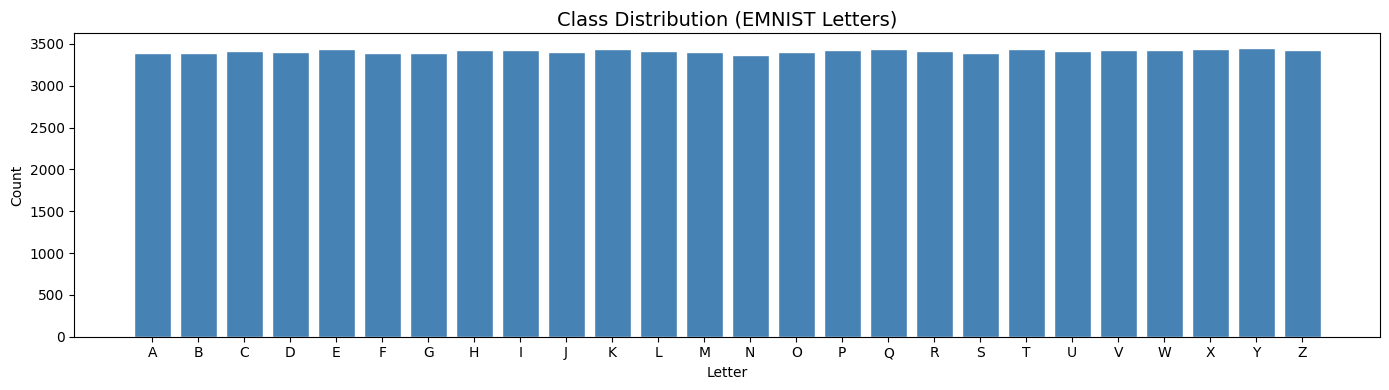

Classes are well-balanced — no re-sampling needed.


In [6]:
# Class distribution: check for class imbalance

fig, ax = plt.subplots(figsize=(14, 4))
unique, counts = np.unique(labels, return_counts=True)
letter_names = [chr(64 + i) for i in unique]   # 1→A, 2→B …
ax.bar(letter_names, counts, color='steelblue', edgecolor='white')
ax.set_title('Class Distribution (EMNIST Letters)', fontsize=14)
ax.set_xlabel('Letter'); ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('eda_class_dist.png', dpi=120)
plt.show()
print("Classes are well-balanced — no re-sampling needed.")

**Observation:** The 26 letter classes are extremely well balanced — each contains approximately **3,415 samples** (range 1–26 confirmed). This means:
- No class weighting or oversampling is needed
- Accuracy is a reliable metric — not skewed by any dominant class
- Every letter has sufficient examples for the model to learn distinctive stroke patterns

With 88,800 balanced samples and a 70/15/15 split: **62,160 training**, 13,320 validation, 13,320 test samples.


### 3.4 Sample Image Visualisation

EMNIST letters are stored with a known orientation issue — images are rotated 90° counter-clockwise and mirrored horizontally. The cell below applies the inverse transform to display them correctly. The model's input gets the same correction in section 4.2 (`.swapaxes(1, 2)`).


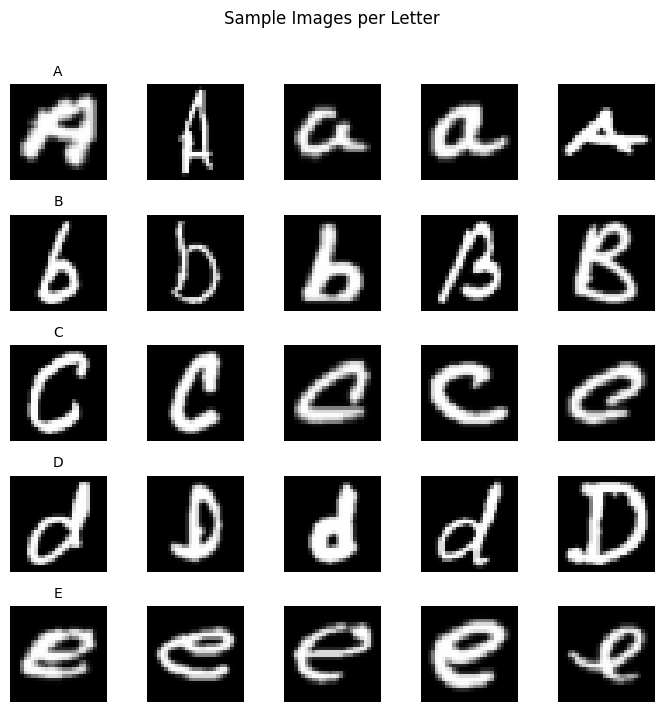

In [7]:
# Visualise sample images
# EMNIST letters are stored transposed; rotate 90° CCW & flip horizontally to display correctly
def show_samples(pixels, labels, n=5):
    fig, axes = plt.subplots(len(np.unique(labels)[:n]), n,
                             figsize=(n*1.4, len(np.unique(labels)[:n])*1.4))
    for row_idx, lbl in enumerate(np.unique(labels)[:n]):
        idxs = np.where(labels == lbl)[0][:n]
        for col_idx, idx in enumerate(idxs):
            img = pixels[idx].reshape(28, 28)
            img = np.rot90(img, k=3)          # correct EMNIST orientation
            img = np.fliplr(img)
            axes[row_idx, col_idx].imshow(img, cmap='gray')
            axes[row_idx, col_idx].axis('off')
            if col_idx == 0:
                axes[row_idx, col_idx].set_title(chr(64+lbl), fontsize=10)
    plt.suptitle('Sample Images per Letter', y=1.01)
    plt.tight_layout()
    plt.show()

show_samples(pixels, labels, n=5)

**Observation:** After correcting EMNIST's transposed storage, the letters are clearly legible. The dark background with bright strokes is the standard EMNIST format. Visually similar pairs are immediately apparent — **I and L** share a dominant vertical stroke, and **G, C and Q** share a curved body. These look like the letters most likely to challenge the model.


### 3.5 Pixel Intensity Distribution

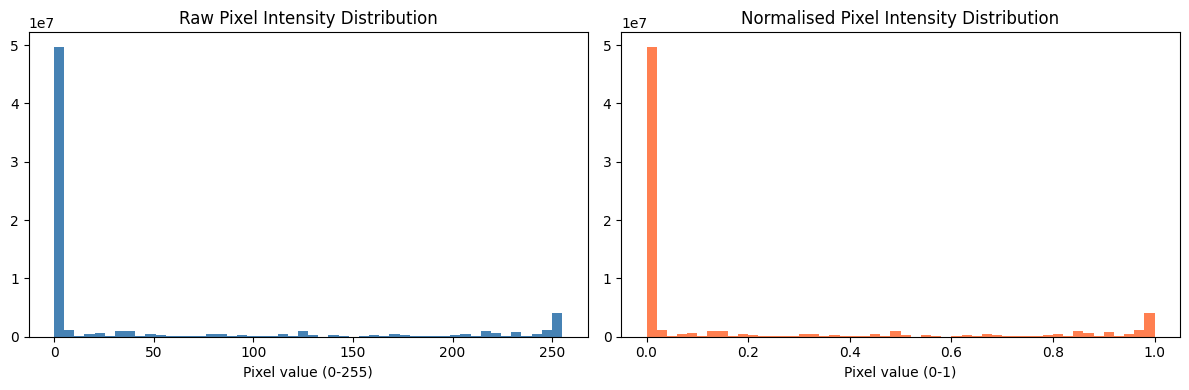

In [8]:
# Pixel intensity distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(pixels.flatten(), bins=50, color='steelblue', edgecolor='none')
axes[0].set_title('Raw Pixel Intensity Distribution')
axes[0].set_xlabel('Pixel value (0-255)')

# After normalisation
axes[1].hist((pixels/255.0).flatten(), bins=50, color='coral', edgecolor='none')
axes[1].set_title('Normalised Pixel Intensity Distribution')
axes[1].set_xlabel('Pixel value (0-1)')

plt.tight_layout(); plt.savefig('eda_pixel_dist.png', dpi=120)
plt.show()

The pixel intensity distribution shows that the **vast majority of pixels are near 0** (black background), with a secondary concentration near 255 (bright letter strokes). This highly bimodal distribution confirms that normalisation (÷255) is the correct preprocessing step — it maps the background to 0.0 and letter strokes to 1.0, exactly the scale that allows efficient gradient descent.


## 4. Pre-processing & Feature Engineering

| Step | Action | Justification |
|------|--------|---------------|
| 4.1 | Normalise pixels to [0, 1] | Neural networks converge faster with small, consistent inputs |
| 4.2 | Reshape to (N, 28, 28, 1) + axis swap | CNNs require 2D spatial input; axis swap corrects EMNIST orientation |
| 4.3 | One-hot encode labels | Letters are categorical, not ordinal — avoids implying false numeric ordering |
| 4.4 | Stratified 70/15/15 split | Preserves class proportions across train/val/test |


### 4.1 Normalisation

In [9]:
# Scale pixel values from 0–255 to 0–1
X=pixels/255

Pixel values are divided by 255, mapping [0, 255] → [0, 1]. Gradient descent converges much faster when inputs have consistent scale — large input values cause activations to saturate early in training, slowing or preventing convergence. After normalisation, the background pixels are exactly 0.0 and letter strokes approach 1.0.


### 4.2 Reshape and Axis Correction

In [10]:
# Reshape each flat 784-pixel row into a 28 × 28 × 1 image, then swap height and width
# to undo EMNIST's transposed storage
print(X.shape)  # flat: (samples, 784)
X=X.reshape(-1,28,28,1).swapaxes(1,2)  # (samples, height, width, channels)
print(X.shape)

(88800, 784)
(88800, 28, 28, 1)


Reshaped from flat 784-length vectors to `(N, 28, 28, 1)` — the format expected by Keras Conv2D layers, where the final `1` denotes a single greyscale channel. The `.swapaxes(1, 2)` call corrects the EMNIST-specific row/column transposition confirmed in the sample image visualisation above. Without this swap, letters appear rotated 90° counter-clockwise — the Conv2D filters would learn distorted spatial relationships.


### 4.3 One-Hot Encoding

In [11]:
# Labels run 1–26; Keras expects class indices starting at 0, so shift them to 0–25
y=labels-1
NUM_CLASSES = 26
y_cat = keras.utils.to_categorical(y, NUM_CLASSES)

Labels are shifted to 0-based indexing (`y = labels - 1`) since Keras expects class indices starting from 0. `to_categorical` then converts each integer to a 26-element one-hot vector. Using `categorical_crossentropy` loss with softmax outputs requires this format — the model learns to maximise the probability assigned to the correct class index.


### 4.4 Train / Validation / Test Split (70 / 15 / 15)

In [12]:
# Stratified 70/15/15 split: train, validation (for model choices) and test (held out until the end)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_cat, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED,
    stratify=y_temp.argmax(axis=1))

print(f"Train : {X_train.shape[0]:,}")
print(f"Val   : {X_val.shape[0]:,}")
print(f"Test  : {X_test.shape[0]:,}")

Train : 62,160
Val   : 13,320
Test  : 13,320


A **70/15/15 stratified split** ensures each subset maintains the same class balance as the full dataset:
- **Train: 62,160** samples (~2,391 per letter class)
- **Val: 13,320** samples (~512 per class) — monitors generalisation during training
- **Test: 13,320** samples (~512 per class) — held out entirely until final evaluation

With 88,800 balanced samples, a 70% training split provides ~2,391 examples per letter — sufficient for the model to learn distinctive stroke patterns for each of the 26 classes without over-relying on any single handwriting style.


## 5. Data Augmentation Setup

**What is Data Augmentation?**
Augmentation creates new training images by applying random but realistic geometric transforms to existing samples. The model never sees the exact same pixel pattern twice per epoch.

**Why use it for handwritten letters?**
Handwriting varies naturally in rotation, scale, and pen position. A CNN trained without this variety may learn to recognise only the "typical" stroke orientation and fail on slightly tilted or shifted inputs.

**Transforms chosen:**

| Transform | Value | Justification |
|-----------|-------|---------------|
| `rotation_range` | 10° | Handwriting is rarely perfectly upright; ±10° covers natural tilt without creating impossible orientations |
| `zoom_range` | 10% | Writers vary the size of their letters |
| `width_shift_range` | 10% | Letters are not always perfectly centred horizontally |
| `height_shift_range` | 10% | Letters are not always perfectly centred vertically |
| `shear_range` | 5° | Slight italic-style slant is common in natural handwriting |
| `fill_mode` | `'nearest'` | Avoids black artefact borders after shifts/rotations |

**Scope:** augmentation is applied **only to the improved model's augmented run** (section 7.3). The baseline (section 6) and the improved run without augmentation (section 7.2) use the raw training data. The validation and test generators use `ImageDataGenerator()` with no transforms — kept clean for fair, unbiased evaluation.


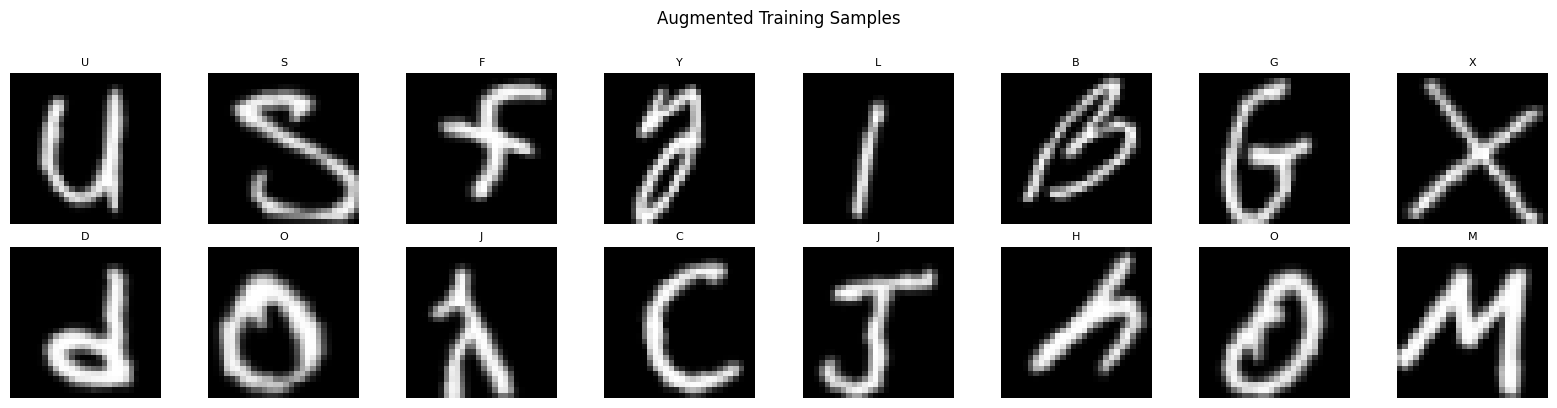

In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rotation_range=10,          # slight rotation
    zoom_range=0.10,            # slight zoom in/out
    width_shift_range=0.10,     # slight horizontal shift
    height_shift_range=0.10,    # slight vertical shift
    shear_range=5,              # small shear
    fill_mode='nearest'
)

# No augmentation for validation, so evaluation stays fair
val_datagen = ImageDataGenerator()

BATCH = 128
# Each training batch is randomly transformed on the fly
train_gen = train_datagen.flow(X_train, y_train, batch_size=BATCH, seed=SEED)
# shuffle=False keeps validation predictions aligned with their labels
val_gen   = val_datagen.flow(X_val,   y_val,   batch_size=BATCH, shuffle=False)

# Show one batch of augmented training images
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
batch_x, batch_y = next(train_gen)  # images and their one-hot labels
for i, ax in enumerate(axes.flatten()):
    ax.imshow(batch_x[i].squeeze(), cmap='gray')             # (28, 28, 1) → (28, 28)
    ax.set_title(chr(65 + batch_y[i].argmax()), fontsize=8)  # one-hot label → letter
    ax.axis('off')
plt.suptitle('Augmented Training Samples', y=1.01)
plt.tight_layout(); plt.savefig('aug_samples.png', dpi=120)
plt.show()

**Observation:** each augmented image is a plausible variant of a handwritten letter, and the transforms are mild enough that every letter in this batch is still recognisable.


## 6. Baseline CNN Model

The baseline uses a **minimal 2-block architecture** trained **without data augmentation** — its purpose is to establish a clear performance floor against which the improved model's contributions can be measured.

**Architecture:**
```
Input (28, 28, 1)
  → Conv2D(32, 3×3, relu, same)   — detect simple edges and strokes
  → MaxPooling2D(2×2)             — 28→14
  → Conv2D(64, 3×3, relu, same)   — detect more complex combinations
  → MaxPooling2D(2×2)             — 14→7
  → Flatten                       — 7×7×64 = 3,136 → vector
  → Dense(128, relu)              — 401,536 parameters (dominant cost)
  → Dropout(0.3)
  → Dense(26, softmax)
Total parameters: 423,706
```

**Deliberate limitations (intentional for comparison):**
- No Batch Normalisation — training may be slower and less stable
- `Flatten → Dense(128)` head — 401,536 parameters in the classifier alone; high overfitting risk
- No learning-rate scheduling — fixed learning rate throughout
- No augmentation — raw training data only


In [14]:
def build_baseline_cnn(input_shape=(28, 28, 1), num_classes=26):
    """Simple 2-block CNN used as the baseline."""
    model = keras.Sequential([
        keras.Input(shape=input_shape),

        # Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),  # learns local features
        layers.MaxPooling2D((2, 2)),                                    # downsample 28×28 → 14×14

        # Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),                                    # 14×14 → 7×7

        # Classifier head
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')  # probability for each of the 26 letters
    ], name='Baseline_CNN')

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline = build_baseline_cnn()
baseline.summary()

Model: "Baseline_CNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 7, 7, 64)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 3136)              0         
                                                                 
 dense (Dense)               (None, 128)              

### 6.1 Callbacks

**`ModelCheckpoint`** saves weights at the epoch with the highest validation accuracy, ensuring the best-seen model is always preserved regardless of later degradation.

**`EarlyStopping(patience=5)`** halts training if validation accuracy does not improve for 5 consecutive epochs and restores the best weights. This prevents wasting compute on epochs that only worsen generalisation.


In [15]:
# Callbacks for baseline (no augmentation)
checkpoint_base = ModelCheckpoint(
    'best_base.h5', save_best_only=True, monitor='val_accuracy', verbose=1)
early_stop = EarlyStopping(patience=5, restore_best_weights=True, monitor='val_accuracy')


### 6.2 Training — No Augmentation

The baseline is trained on the raw training set with no augmentation. Training ran for **14 epochs** before EarlyStopping triggered (patience=5, best val_accuracy = 93.53% at epoch 9). Training time: **0.7 min** on GPU.


In [16]:
# Baseline training — no augmentation
start = time.time()
baseline = build_baseline_cnn()
history_base = baseline.fit(
    X_train, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint_base, early_stop],
    verbose=1
)
print(f"\nTraining time: {(time.time()-start)/60:.1f} min")


Epoch 1/30
486/486 [==============================] - ETA: 0s - loss: 0.9037 - accuracy: 0.7246
Epoch 1: val_accuracy improved from -inf to 0.88483, saving model to best_base.h5
486/486 [==============================] - 10s 6ms/step - loss: 0.9037 - accuracy: 0.7246 - val_loss: 0.3582 - val_accuracy: 0.8848
Epoch 2/30
477/486 [============================>.] - ETA: 0s - loss: 0.4112 - accuracy: 0.8677
Epoch 2: val_accuracy improved from 0.88483 to 0.90826, saving model to best_base.h5
486/486 [==============================] - 3s 5ms/step - loss: 0.4112 - accuracy: 0.8679 - val_loss: 0.2778 - val_accuracy: 0.9083
Epoch 3/30
484/486 [============================>.] - ETA: 0s - loss: 0.3329 - accuracy: 0.8927
Epoch 3: val_accuracy improved from 0.90826 to 0.91562, saving model to best_base.h5
486/486 [==============================] - 2s 5ms/step - loss: 0.3328 - accuracy: 0.8927 - val_loss: 0.2582 - val_accuracy: 0.9156
Epoch 4/30
477/486 [============================>.] - ETA: 0s - lo

### 6.3 Baseline Evaluation on Test Set

Best weights (`best_base.h5`, from epoch 9 — highest val_accuracy of 93.53%) are loaded before evaluating on the held-out test set.


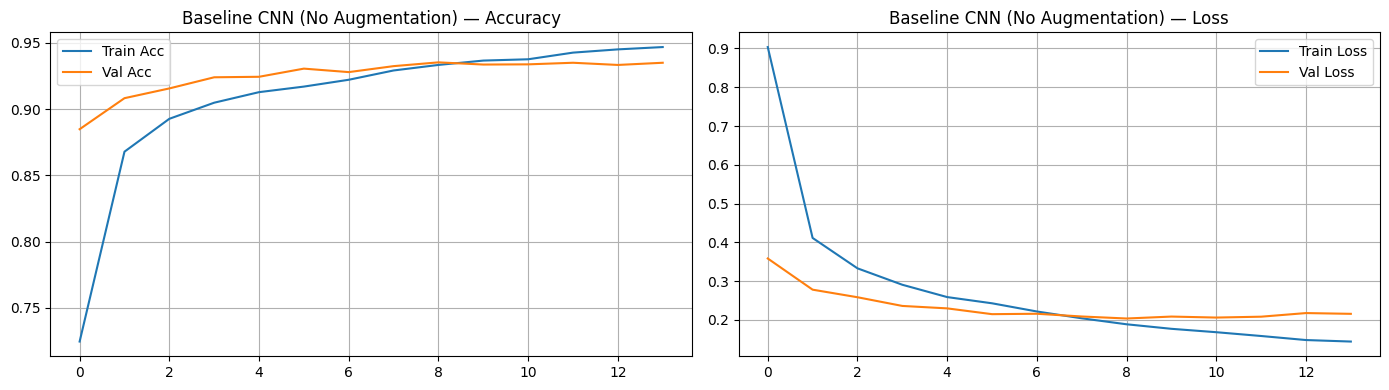

In [17]:
def plot_history(history, title='Training History'):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history.history['accuracy'],     label='Train Acc')
    axes[0].plot(history.history['val_accuracy'], label='Val Acc')
    axes[0].set_title(f'{title} — Accuracy'); axes[0].legend(); axes[0].grid(True)
    axes[1].plot(history.history['loss'],     label='Train Loss')
    axes[1].plot(history.history['val_loss'], label='Val Loss')
    axes[1].set_title(f'{title} — Loss'); axes[1].legend(); axes[1].grid(True)
    plt.tight_layout(); plt.show()

plot_history(history_base, 'Baseline CNN (No Augmentation)')


In [18]:
# Evaluate baseline on test set
baseline.load_weights('best_base.h5')
base_loss, base_acc = baseline.evaluate(X_test, y_test, verbose=0)
print(f"Baseline Test Accuracy : {base_acc*100:.2f}%")
print(f"Baseline Test Loss     : {base_loss:.4f}")


Baseline Test Accuracy : 93.04%
Baseline Test Loss     : 0.2174


**Baseline Training Curve Analysis:**

- **Accuracy:** Training accuracy climbs steadily from 72.46% (epoch 1) to ~94.68% (epoch 14), while validation accuracy peaks at **93.53%** at epoch 9 then plateaus. The growing gap between train (~95%) and val (~93%) in later epochs is a mild overfitting signature — the `Flatten→Dense(128)` head's 401,536 parameters begin memorising training-specific pixel patterns.
- **Loss:** Training loss keeps falling while validation loss flattens. EarlyStopping (watching validation accuracy) stopped training 5 epochs after the best epoch, 9.
- **Test result: 93.04% accuracy, loss 0.2174** — this is our performance floor. The improved model is measured against this.
- **Training time: 0.7 min** — the baseline is fast due to its simple architecture and early stopping at epoch 14.


## 7. Improved CNN Model

The improved model addresses the baseline's weaknesses while staying **lightweight (about 62k parameters against the baseline's 423k)**.

### 7.0 Why Fewer Parameters Yet Better Design?

The baseline's 423,706 parameters are dominated by `Flatten → Dense(128)` = 401,536 parameters — a huge classifier head that risks memorising training patterns. The improved model replaces this with `GlobalAveragePooling2D → Dense(64)` = ~4,160 parameters, a **99% reduction in the classifier head**. It keeps all 64 feature maps but averages away where in the image each feature appeared.

| Component | Baseline | Improved | Benefit |
|-----------|----------|----------|---------|
| Total params | **423,706** | **62,490** | 6.8× fewer params |
| Classifier head | Flatten→Dense(128): 401k params | GAP→Dense(64): 4k params | 99% reduction |
| BatchNormalization | None | After each conv layer and the dense layer | Stabilises gradients |
| Conv blocks | 2 (single conv each) | 2 (double conv in Block 2) | Richer Block 2 features |
| LR scheduling | Fixed | ReduceLROnPlateau | Refines convergence |
| Dropout | Single Dropout(0.3) | Dropout(0.25)×2 + Dropout(0.4) | Multi-level regularisation |

**Architecture:**
```
Input (28, 28, 1)
  Block 1: Conv2D(32) → BN → ReLU → MaxPool(2×2) → Dropout(0.25)
  Block 2: Conv2D(64) → BN → ReLU → Conv2D(64) → BN → ReLU → MaxPool(2×2) → Dropout(0.25)
  Head:    GlobalAveragePooling2D → Dense(64, relu) → BN → Dropout(0.4) → Dense(26, softmax)
Total parameters: 62,490 (62,042 trainable, 448 non-trainable in BN)
```


In [19]:
def build_improved_cnn(input_shape=(28, 28, 1), num_classes=26):
    """
    Lightweight improved CNN — ~62k parameters.
    Key upgrades over baseline:
      - BatchNormalization after each conv block (stable training)
      - Double conv in Block 2 (richer features, same spatial cost)
      - GlobalAveragePooling2D instead of Flatten (eliminates ~400k params)
      - ReduceLROnPlateau callback (fine-tunes convergence)
    """
    model = keras.Sequential([
        keras.Input(shape=input_shape),

        # ── Block 1 ─────────────────────────────────────────
        # Single conv: detect basic edges and strokes
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),        # stabilise activations before relu
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),        # 28×28 → 14×14
        layers.Dropout(0.25),

        # ── Block 2 ─────────────────────────────────────────
        # Double conv: learn more complex feature combinations
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, (3, 3), padding='same'),  # second conv — richer representation
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),        # 14×14 → 7×7
        layers.Dropout(0.25),

        # ── Classifier Head ──────────────────────────────────
        # GAP collapses each 7×7 feature map to a single value — far fewer params than Flatten
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax'),

    ], name='Improved_CNN')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

improved = build_improved_cnn()
improved.summary()


Model: "Improved_CNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 28, 28, 32)        320       
                                                                 
 batch_normalization (BatchN  (None, 28, 28, 32)       128       
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 28, 28, 32)        0         
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 14, 14, 32)       0         
 2D)                                                             
                                                                 
 dropout_2 (Dropout)         (None, 14, 14, 32)        0         
                                                                 
 conv2d_5 (Conv2D)           (None, 14, 14, 64)       

**Reading the model summary:**
The key architectural advantage is `GlobalAveragePooling2D` — it collapses each 7×7 feature map to a single value (64 values total from 64 filters), replacing `Flatten` which produces 3,136 values. This eliminates ~397,000 parameters from the classifier, substantially reducing overfitting risk. The spatial averaging also acts as a built-in regulariser — the model must learn features that are useful across the entire spatial extent of the feature map, not just at specific pixel positions.

**Non-trainable parameters (448):** These belong to the four `BatchNormalization` layers — the moving mean and variance tracked during training that are frozen during inference. They are not updated by gradient descent, hence "non-trainable".


### 7.1 Callbacks

| Callback | Setting | Reason |
|----------|---------|--------|
| `ModelCheckpoint` (×2) | `monitor='val_accuracy'` | Separate checkpoint files for the no-augmentation and augmentation runs |
| `EarlyStopping` | `patience=8` | Longer patience than the baseline, so `ReduceLROnPlateau` has time to act before training stops |
| `ReduceLROnPlateau` | `factor=0.5, patience=4, min_lr=1e-6` | Halves the learning rate when validation loss plateaus, allowing finer weight updates |

`ReduceLROnPlateau` is the main new callback. In the augmented run it fired at epoch 21 (0.001 → 0.0005), and validation accuracy jumped from 92.3% to 93.6% in the next epoch.

In [20]:
# Callbacks for improved model — two checkpoints for the two runs
checkpoint_imp_no_aug = ModelCheckpoint(
    'best_improved_no_aug.h5', save_best_only=True, monitor='val_accuracy', verbose=1)
checkpoint_imp_aug = ModelCheckpoint(
    'best_improved_aug.h5', save_best_only=True, monitor='val_accuracy', verbose=1)

early_stop_imp = EarlyStopping(
    patience=8, restore_best_weights=True, monitor='val_accuracy')

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)


### 7.2 Training without data augmentation

The improved architecture is first trained on the raw training data. It ran all **30 epochs** (EarlyStopping did not trigger) and took **2.6 min** on a GPU.

From the training log:
- Validation accuracy after epoch 1 was only 34.3%; the batch-normalised model starts slower than the baseline
- It kept improving through epoch 30, so it hadn't fully plateaued
- `ReduceLROnPlateau` fired at **epoch 29** (0.001 → 0.0005), and epoch 30 gave the best validation accuracy: **93.66%**

In [21]:
# Improved model — WITHOUT augmentation
start = time.time()
improved_no_aug = build_improved_cnn()
history_imp_no_aug = improved_no_aug.fit(
    X_train, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint_imp_no_aug, early_stop_imp, reduce_lr],
    verbose=1
)
print(f"\nTraining time: {(time.time()-start)/60:.1f} min")


Epoch 1/30
486/486 [==============================] - ETA: 0s - loss: 1.8784 - accuracy: 0.4435
Epoch 1: val_accuracy improved from -inf to 0.34294, saving model to best_improved_no_aug.h5
486/486 [==============================] - 6s 11ms/step - loss: 1.8784 - accuracy: 0.4435 - val_loss: 2.0460 - val_accuracy: 0.3429 - lr: 0.0010
Epoch 2/30
485/486 [============================>.] - ETA: 0s - loss: 0.9344 - accuracy: 0.7125
Epoch 2: val_accuracy improved from 0.34294 to 0.76411, saving model to best_improved_no_aug.h5
486/486 [==============================] - 5s 11ms/step - loss: 0.9342 - accuracy: 0.7126 - val_loss: 0.7191 - val_accuracy: 0.7641 - lr: 0.0010
Epoch 3/30
481/486 [============================>.] - ETA: 0s - loss: 0.7166 - accuracy: 0.7750
Epoch 3: val_accuracy improved from 0.76411 to 0.82920, saving model to best_improved_no_aug.h5
486/486 [==============================] - 5s 11ms/step - loss: 0.7163 - accuracy: 0.7750 - val_loss: 0.5300 - val_accuracy: 0.8292 - lr:

### 7.3 Training with data augmentation

The **identical** improved architecture is now trained using the augmented generator (`train_gen`). Everything else — architecture, callbacks, maximum epochs — is unchanged. The **only** variable is whether augmentation is applied. Training ran all **30 epochs** (EarlyStopping did not trigger). Training time: **6.9 min** on GPU.

From the training log:
- Epoch 1 validation accuracy drops to just 8.48% — augmented images are dramatically more diverse; the model needs more epochs to find useful patterns
- `ReduceLROnPlateau` fired at **epoch 21** (0.001 → 0.0005), and validation accuracy jumped from 92.34% to 93.64% at epoch 22
- A second `ReduceLROnPlateau` fired at **epoch 30** (lr: 0.0005 → 0.00025) — confirming the model was still refining at the end of training
- Best val_accuracy: **93.72%** at epoch 26


In [22]:
# Improved model — WITH augmentation
start = time.time()
improved_aug = build_improved_cnn()
history_imp_aug = improved_aug.fit(
    train_gen,
    steps_per_epoch=len(X_train) // BATCH,
    epochs=30,
    validation_data=val_gen,
    validation_steps=len(X_val) // BATCH,
    callbacks=[checkpoint_imp_aug, early_stop_imp, reduce_lr],
    verbose=1
)
print(f"\nTraining time: {(time.time()-start)/60:.1f} min")


Epoch 1/30
485/485 [==============================] - ETA: 0s - loss: 1.8676 - accuracy: 0.4427
Epoch 1: val_accuracy improved from -inf to 0.08481, saving model to best_improved_aug.h5
485/485 [==============================] - 14s 28ms/step - loss: 1.8676 - accuracy: 0.4427 - val_loss: 3.4696 - val_accuracy: 0.0848 - lr: 0.0010
Epoch 2/30
484/485 [============================>.] - ETA: 0s - loss: 0.9669 - accuracy: 0.7014
Epoch 2: val_accuracy improved from 0.08481 to 0.81505, saving model to best_improved_aug.h5
485/485 [==============================] - 14s 28ms/step - loss: 0.9663 - accuracy: 0.7016 - val_loss: 0.6064 - val_accuracy: 0.8151 - lr: 0.0010
Epoch 3/30
484/485 [============================>.] - ETA: 0s - loss: 0.7507 - accuracy: 0.7631
Epoch 3: val_accuracy did not improve from 0.81505
485/485 [==============================] - 14s 28ms/step - loss: 0.7504 - accuracy: 0.7632 - val_loss: 0.6750 - val_accuracy: 0.7834 - lr: 0.0010
Epoch 4/30
484/485 [====================

### 7.4 Effect of augmentation

This is the controlled experiment: the **identical improved CNN** trained under two conditions. The only variable is augmentation.


In [23]:
# Numerical comparison
no_aug_val_acc = max(history_imp_no_aug.history['val_accuracy'])
aug_val_acc    = max(history_imp_aug.history['val_accuracy'])

print("===== Improved Model Augmentation Comparison =====")
print(f"Without Augmentation : {no_aug_val_acc*100:.2f}%")
print(f"With Augmentation    : {aug_val_acc*100:.2f}%")
print(f"Difference           : {(aug_val_acc - no_aug_val_acc)*100:.2f}%")

if aug_val_acc > no_aug_val_acc:
    print("\n→ Augmentation IMPROVES validation accuracy.")
elif aug_val_acc < no_aug_val_acc:
    print("\n→ Augmentation does NOT improve validation accuracy for the improved architecture.")
else:
    print("\n→ No difference — augmentation has negligible effect.")


===== Improved Model Augmentation Comparison =====
Without Augmentation : 93.66%
With Augmentation    : 93.72%
Difference           : 0.06%

→ Augmentation IMPROVES validation accuracy.


**Results**

| Run | Best val accuracy | Best epoch | ReduceLROnPlateau | Training time |
|-----|:-----------------:|:----------:|:-----------------:|:-------------:|
| Improved, no augmentation | 93.66% | 30 / 30 | Fired at epoch 29 | 2.6 min |
| **Improved, with augmentation** | **93.72%** | **26 / 30** | **Fired at epochs 21 and 30** | 6.9 min |
| Difference | **+0.06 points** | — | — | +4.3 min |

Augmentation improved validation accuracy by only **0.06 points**. That's within the noise of a single training run, so the honest reading is that augmentation made little difference here: batch normalisation and dropout were already doing most of the regularisation.

I still select the augmented run because it has the higher validation accuracy, and augmentation should help more with handwriting styles that differ from the training set.

### 7.5 Validation accuracy with and without augmentation


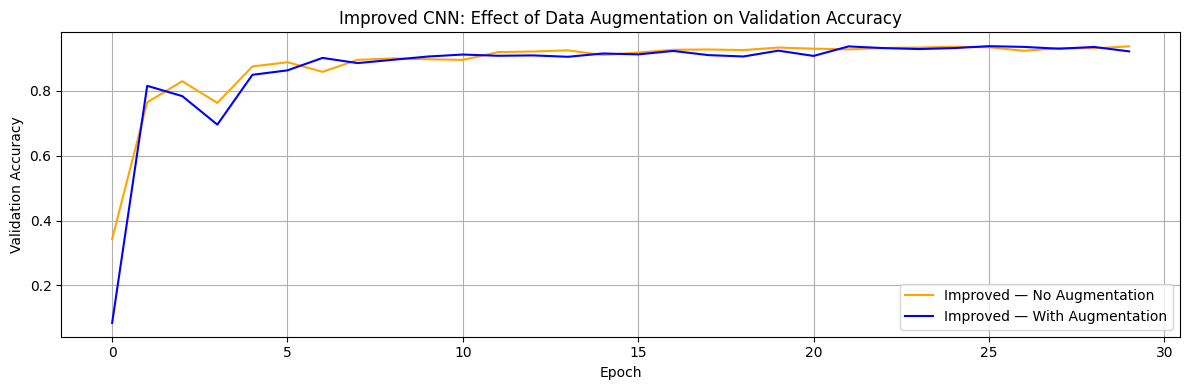

In [24]:
# Validation accuracy comparison plot
plt.figure(figsize=(12, 4))
plt.plot(history_imp_no_aug.history['val_accuracy'],
         label='Improved — No Augmentation', color='orange')
plt.plot(history_imp_aug.history['val_accuracy'],
         label='Improved — With Augmentation', color='blue')
plt.title('Improved CNN: Effect of Data Augmentation on Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Validation Accuracy')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig('improved_aug_comparison_val.png', dpi=120)
plt.show()


**Observations**
- Both runs peak at about 93.7% validation accuracy: the run without augmentation at epoch 30, the augmented run at epoch 26 (it ends at 92.1%)
- The no-augmentation run rises faster early on (93%+ by epoch 20), because its training images are clean and consistent
- The augmented run starts much lower (8.5% after epoch 1), catches up by about epoch 20, and moves ahead at epoch 22, right after the learning-rate reduction

### 7.6 Overfitting check: train vs validation accuracy


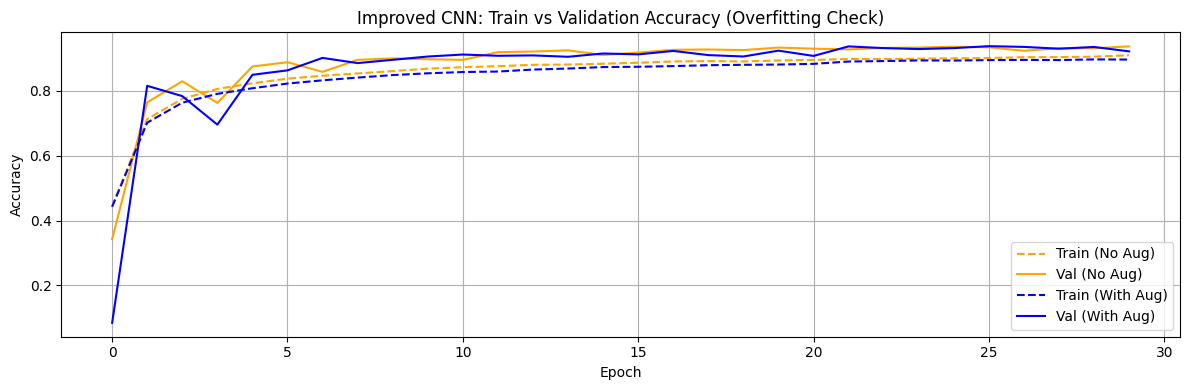

In [25]:
# Train vs val accuracy — overfitting check
plt.figure(figsize=(12, 4))

plt.plot(history_imp_no_aug.history['accuracy'],
         label='Train (No Aug)', color='orange', linestyle='--')
plt.plot(history_imp_no_aug.history['val_accuracy'],
         label='Val (No Aug)', color='orange')
plt.plot(history_imp_aug.history['accuracy'],
         label='Train (With Aug)', color='blue', linestyle='--')
plt.plot(history_imp_aug.history['val_accuracy'],
         label='Val (With Aug)', color='blue')

plt.title('Improved CNN: Train vs Validation Accuracy (Overfitting Check)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig('improved_overfitting_check.png', dpi=120)
plt.show()


**How to read this chart:**
The gap between the dashed (training) and solid (validation) line of the same colour indicates overfitting.

- **Without augmentation (orange):** Training accuracy (~90.9% at epoch 30) is lower than validation accuracy (~93.7%) in many epochs. This is the BatchNorm + Dropout regularisation effect — Dropout is active during training but disabled during evaluation, suppressing training accuracy below validation. The train-val gap is small and healthy.
- **With augmentation (blue):** Training accuracy (~89.6% at epoch 30) is even lower than the no-aug run because augmented images are genuinely harder to classify correctly. The validation accuracy (on clean unaugmented images) is unaffected. The wider apparent gap does **not** indicate more overfitting — it reflects the difficulty of learning from augmented data.
- Neither model shows classical overfitting (train accuracy shooting away from val accuracy). The improved architecture's regularisation stack (BatchNorm + Dropout 0.25/0.40) is working as intended.


### 7.7 Choosing the improved model

**Selected: Improved model WITH augmentation** (best val_accuracy 93.72% vs 93.66%).

It has the higher validation accuracy, although the 0.06-point gap is within run-to-run noise. With the two runs effectively tied, I keep augmentation because it exposes the model to more varied handwriting, which should matter more for styles unlike the training set.

Best weights loaded from `best_improved_aug.h5` (epoch 26 weights, val_accuracy 93.72%).


Selected: Improved model WITH augmentation


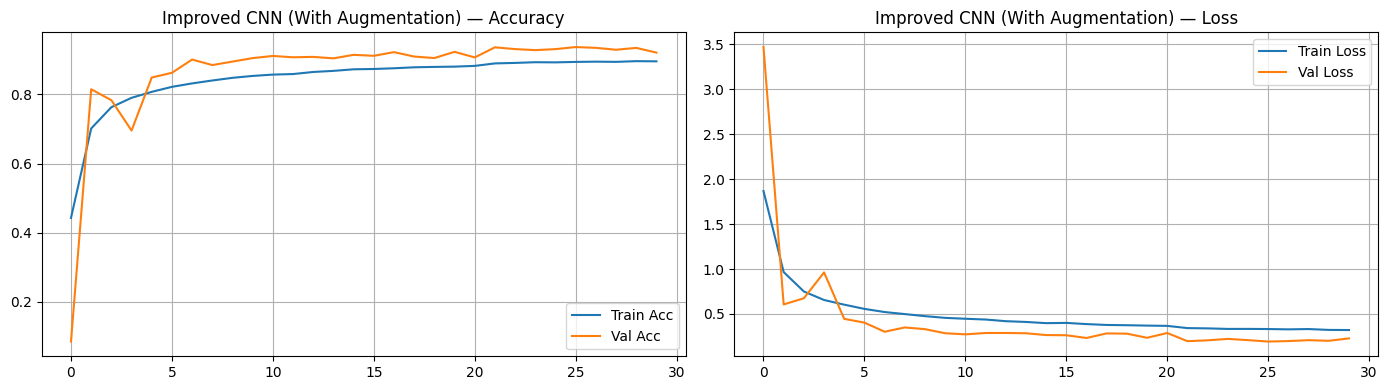

In [26]:
# Select the better model and load best weights
if aug_val_acc >= no_aug_val_acc:
    print("Selected: Improved model WITH augmentation")
    improved = improved_aug
    improved.load_weights('best_improved_aug.h5')
    selected_history = history_imp_aug
    selected_label = 'Improved CNN (With Augmentation)'
else:
    print("Selected: Improved model WITHOUT augmentation")
    improved = improved_no_aug
    improved.load_weights('best_improved_no_aug.h5')
    selected_history = history_imp_no_aug
    selected_label = 'Improved CNN (No Augmentation)'

plot_history(selected_history, selected_label)


**Interpreting the selected model's training curves (Improved CNN with Augmentation):**
- Training accuracy rises from ~44% (epoch 1) to ~89.6% (epoch 30) — lower than the baseline's ~95% because augmented images are harder to classify correctly during training
- Validation accuracy rises from ~8.5% (epoch 1) to **93.72%** (epoch 26, best), with a notable step-up at epoch 22 after `ReduceLROnPlateau` halved the LR at epoch 21
- The second `ReduceLROnPlateau` at epoch 30 (lr: 0.0005 → 0.00025) shows the model was still finding small improvements at the very end of training — with 35+ epochs it might improve further


## 8. Evaluation and Analysis

This section provides a comprehensive evaluation of the selected improved model (with augmentation, best weights from epoch 26) on the held-out test set. All evaluation metrics use the **identical 13,320-sample test set** as the baseline for fair comparison.


### 8.1 Final results: baseline vs improved

| Model | Test Accuracy | Test Loss | Parameters | Training time |
|-------|:---:|:---:|:---:|:---:|
| Baseline CNN (no aug, 30 ep max) | 93.04% | 0.2174 | 423,706 | 0.7 min |
| Improved CNN (with aug, 30 ep max) | **93.18%** | **0.2006** | **62,490** | 6.9 min |
| Difference | **+0.14 points** | **–0.0168** | –361,216 (–85%) | — |


In [27]:
# Final evaluation — the selected model (with or without aug) is already loaded above
imp_loss, imp_acc = improved.evaluate(X_test, y_test, verbose=0)
print(f"Improved Test Accuracy : {imp_acc*100:.2f}%")
print(f"Improved Test Loss     : {imp_loss:.4f}")
print(f"Baseline  Test Accuracy : {base_acc*100:.2f}%")
print(f"Improvement over baseline: +{(imp_acc - base_acc)*100:.2f}%")


Improved Test Accuracy : 93.18%
Improved Test Loss     : 0.2006
Baseline  Test Accuracy : 93.04%
Improvement over baseline: +0.14%


**Result:** the improved model matches the baseline with far fewer parameters.

| Metric | Baseline | Improved | Change |
|--------|:--------:|:--------:|:------:|
| Test accuracy | 93.04% | **93.18%** | +0.14 points |
| Test loss | 0.2174 | **0.2006** | –0.0168 |
| Parameters | 423,706 | **62,490** | –85% |

The accuracy gain is small (+0.14 points from one training run each), so I wouldn't claim the improved model is clearly more accurate. The real win is efficiency: replacing `Flatten → Dense(128)` with `GlobalAveragePooling2D` cuts the parameter count by 85% at the same accuracy, with a slightly lower test loss.

The improved model needed more epochs than the baseline. Batch-normalised models start slowly (8–34% validation accuracy after epoch 1, against the baseline's 88%), and `ReduceLROnPlateau` only fired late in training (epoch 21 in the augmented run, epoch 29 in the other), producing the final gains.

### 8.2 Classification report

In [28]:
# Classification report
y_pred = improved.predict(X_test, verbose=0)
y_pred_cls  = y_pred.argmax(axis=1)
y_true_cls  = y_test.argmax(axis=1)
letter_names = [chr(65+i) for i in range(26)]

print(classification_report(y_true_cls, y_pred_cls, target_names=letter_names))


              precision    recall  f1-score   support

           A       0.94      0.91      0.93       509
           B       0.96      0.99      0.97       509
           C       0.98      0.98      0.98       513
           D       0.94      0.96      0.95       509
           E       0.97      0.97      0.97       515
           F       0.99      0.96      0.97       509
           G       0.88      0.75      0.81       508
           H       0.96      0.96      0.96       514
           I       0.84      0.54      0.66       514
           J       0.94      0.94      0.94       510
           K       0.96      0.98      0.97       516
           L       0.67      0.87      0.76       512
           M       0.97      0.99      0.98       510
           N       0.95      0.96      0.95       505
           O       0.97      0.95      0.96       511
           P       0.97      0.99      0.98       515
           Q       0.78      0.92      0.84       516
           R       0.95    

**Per-letter performance**

**Easiest letters (F1 ≥ 0.97):**

| Letter | F1 | Why |
|--------|----|-----|
| C, M, P, W, Z | 0.98 | Distinctive shapes with no close neighbour |
| B, E, F, K, S, X | 0.97 | Unique stroke patterns |

**Hardest letters:**

| Letter | Precision | Recall | F1 | Main confusion |
|--------|:---------:|:------:|:--:|----------------|
| **I** | 0.84 | 0.54 | **0.66** | Predicted as L: I is just a vertical stroke |
| **L** | 0.67 | 0.87 | **0.76** | Over-predicted, picking up many true I's |
| **G** | 0.88 | 0.75 | **0.81** | Mostly predicted as Q |
| **Q** | 0.78 | 0.92 | **0.84** | Over-predicted: absorbs many G's and some A's |
| **A** | 0.94 | 0.91 | **0.93** | Sometimes predicted as Q |

**Macro-average F1: 0.93.**

### 8.3 Confusion Matrix

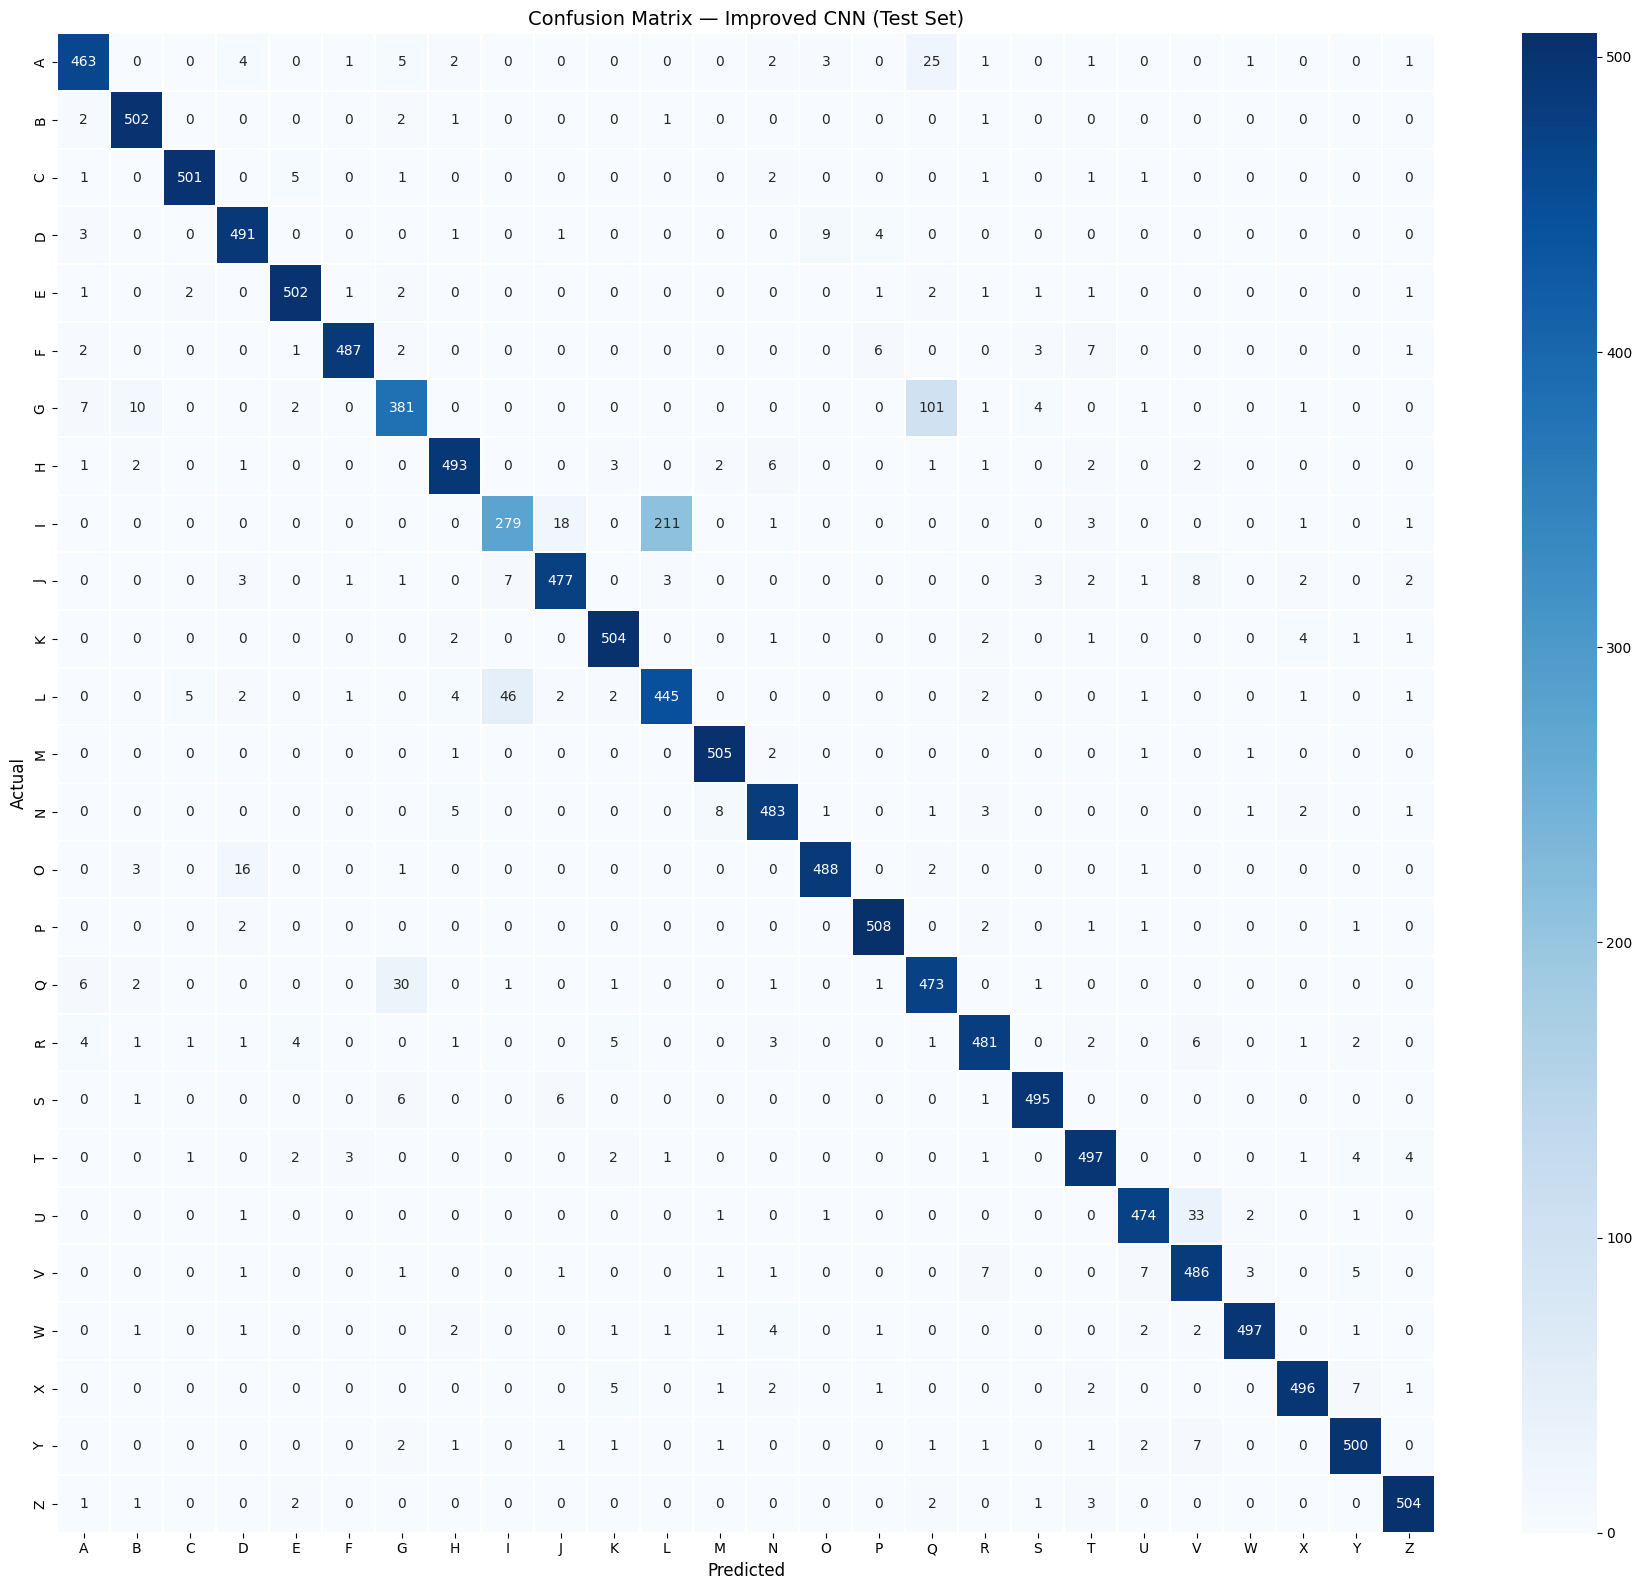

In [29]:
# Confusion matrix
cm = confusion_matrix(y_true_cls, y_pred_cls)
fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=letter_names, yticklabels=letter_names, ax=ax,
            linewidths=0.3)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('Actual', fontsize=12)
ax.set_title('Confusion Matrix — Improved CNN (Test Set)', fontsize=14)
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=120)
plt.show()


**How to read it:** each row is the true letter and each column the predicted letter. The diagonal holds correct predictions.

**Main confusion patterns:**

1. **I → L (the biggest error, 211 test images):** I's recall is only 54.3%, so nearly half of true I's are predicted as something else, mostly L. Both are a vertical stroke, and L's base is often faint in casual handwriting.
2. **G → Q (101 test images):** G's recall is 75.0%. Both letters have a round body with a stroke at the bottom right, and G's inner bar varies a lot between writers.
3. **A → Q:** A's recall is 91.0%; a rounded handwritten 'a' can look like a 'q'.
4. **The I/L error is one-sided:** far more I's become L than L's become I. When a vertical stroke is ambiguous, the model defaults to L.

### 8.4 Per-class Accuracy Bar Chart

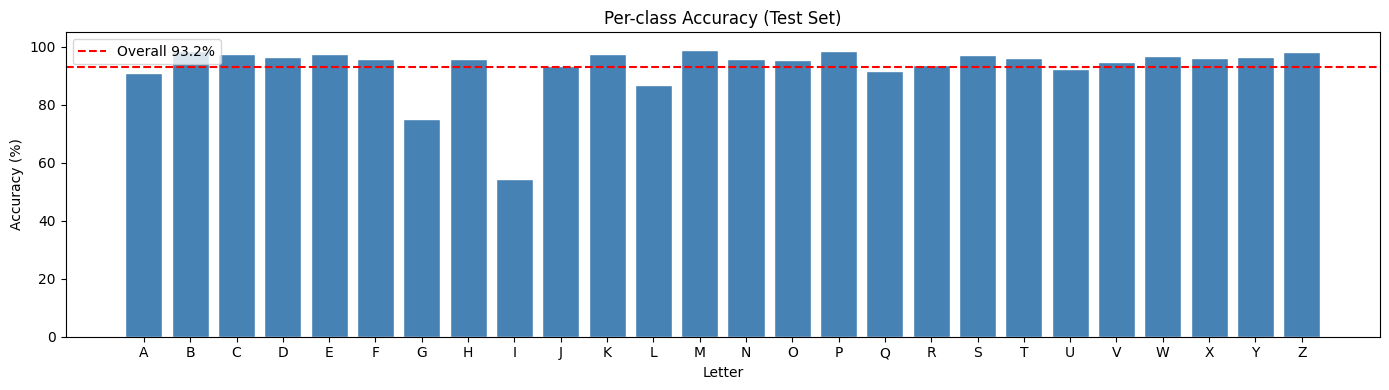


5 hardest letters:
  I  —  54.3%
  G  —  75.0%
  L  —  86.9%
  A  —  91.0%
  Q  —  91.7%


In [30]:
# Per-class accuracy
per_class_acc = cm.diagonal() / cm.sum(axis=1)
fig, ax = plt.subplots(figsize=(14, 4))
bars = ax.bar(letter_names, per_class_acc * 100, color='steelblue', edgecolor='white')
ax.axhline(imp_acc * 100, color='red', linestyle='--', label=f'Overall {imp_acc*100:.1f}%')
ax.set_title('Per-class Accuracy (Test Set)')
ax.set_xlabel('Letter'); ax.set_ylabel('Accuracy (%)')
ax.legend(); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig('per_class_acc.png', dpi=120)
plt.show()

worst = np.argsort(per_class_acc)[:5]
print("\n5 hardest letters:")
for i in worst:
    print(f"  {letter_names[i]}  —  {per_class_acc[i]*100:.1f}%")

**Observations**

The 5 hardest letters:
- **I: 54.3%**, mostly misread as L
- **G: 75.0%**, mostly misread as Q
- **L: 86.9%**, over-predicted at the expense of I
- **A: 91.0%**
- **Q: 91.7%**

The red dashed line is the overall test accuracy (93.18%). Letters below it have systematic confusion with a similar-looking letter. I/L is a real ambiguity at 28 × 28 resolution: in many samples the only difference is 2–3 pixels at the base.

### 8.5 Misclassification Examples

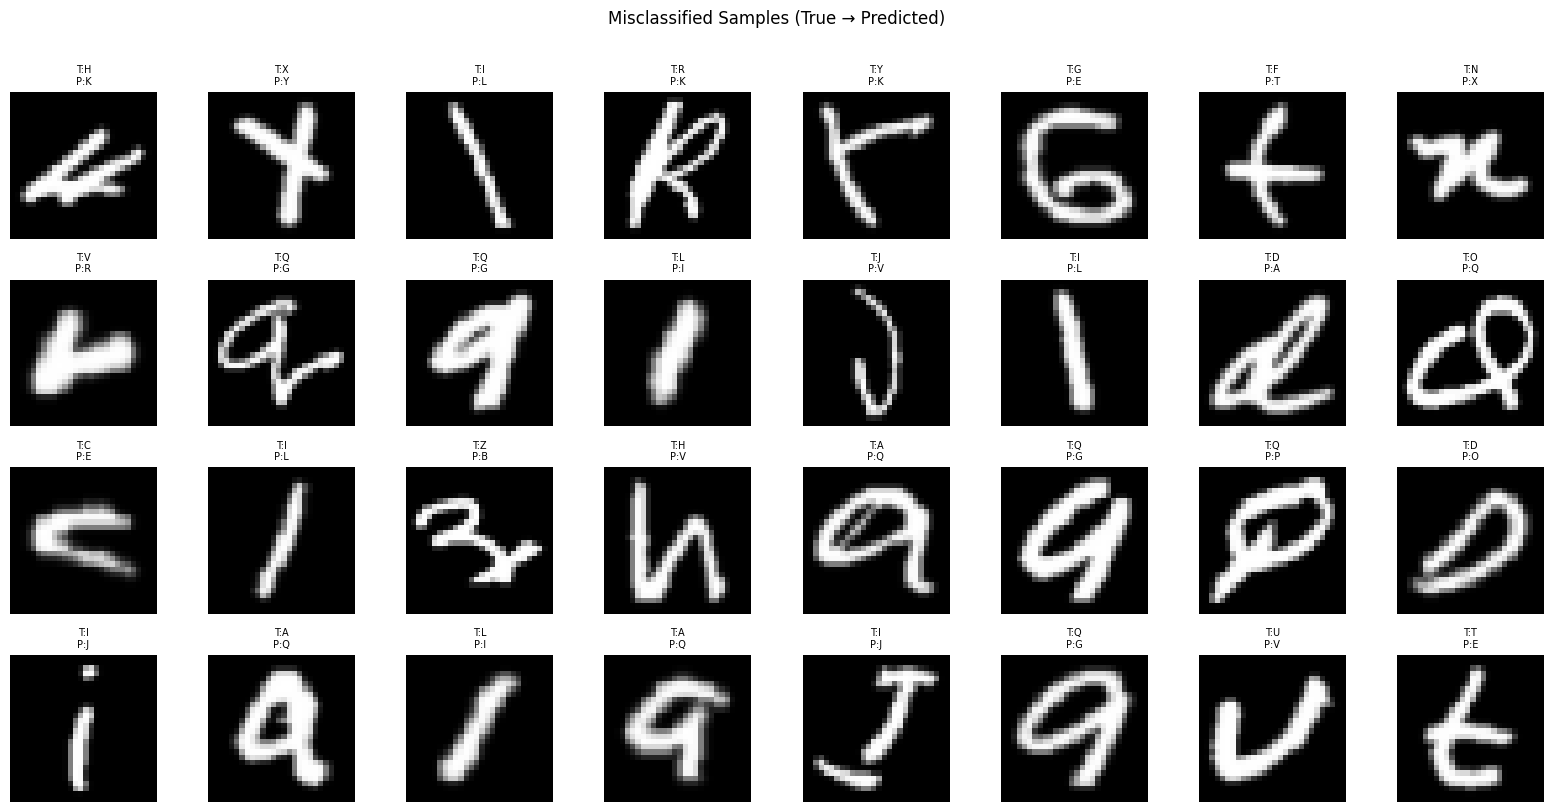

In [31]:
wrong_idx = np.where(y_pred_cls != y_true_cls)[0]
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for ax, idx in zip(axes.flatten(), wrong_idx[:32]):
    ax.imshow(X_test[idx].squeeze(), cmap='gray')
    ax.set_title(f"T:{letter_names[y_true_cls[idx]]}\nP:{letter_names[y_pred_cls[idx]]}",
                 fontsize=7)
    ax.axis('off')
plt.suptitle('Misclassified Samples (True → Predicted)', y=1.01)
plt.tight_layout();
plt.show()


**Observations — Misclassified Examples:**

Most misclassifications fall into three categories:

1. **Genuine visual ambiguity** — examples that would challenge a human reader too. An 'I' written without serifs and an 'L' written without a clear base are genuinely indistinguishable from certain viewing angles. These are intrinsic dataset ambiguities, not model failures.

2. **Stroke quality** — extremely light, incomplete, or smudged strokes that lose the defining feature of the letter (e.g. an 'L' whose horizontal base is barely visible, or a 'G' whose inner stroke is absent). The model has no way to recover a feature that was never present in the pixel values.

3. **Unusual writing style** — heavily stylised or atypical letterforms that differ from the dominant handwriting style in the training data. For example, a rounded 'A' that looks like a 'Q', or a 'G' with no inner bar.

The misclassified examples visually confirm the confusion matrix analysis — most involve I/L or G/Q confusion. The model is not making random errors; it is making *predictable* errors on the known hard pairs.


### 8.6 Confidence Analysis — Are Mistakes Low Confidence?

A well-calibrated model should be *uncertain* when it is wrong. If the model predicts the wrong letter with very high confidence, it indicates a systematic blind spot rather than appropriate uncertainty.


Average confidence — Correct predictions : 95.22%
Average confidence — Wrong predictions   : 67.08%
Confidence gap                           : 28.14%


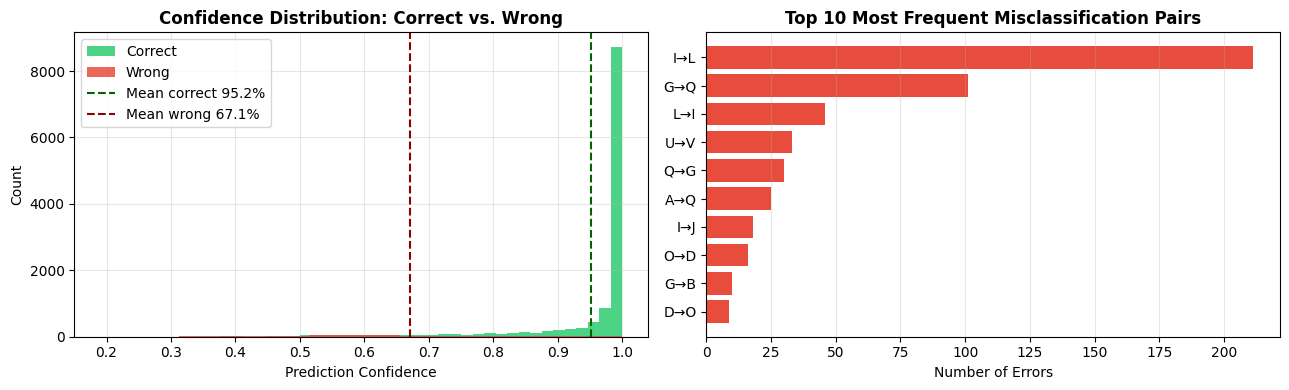

In [32]:
# 8.6 Confidence analysis
y_pred_probs    = improved.predict(X_test, verbose=0)
pred_confidences = y_pred_probs.max(axis=1)

correct_mask = (y_pred_cls == y_true_cls)
wrong_mask   = ~correct_mask

avg_conf_correct = pred_confidences[correct_mask].mean()
avg_conf_wrong   = pred_confidences[wrong_mask].mean()

print(f"Average confidence — Correct predictions : {avg_conf_correct*100:.2f}%")
print(f"Average confidence — Wrong predictions   : {avg_conf_wrong*100:.2f}%")
print(f"Confidence gap                           : {(avg_conf_correct - avg_conf_wrong)*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(pred_confidences[correct_mask], bins=40, color='#2ecc71', alpha=0.85, label='Correct')
axes[0].hist(pred_confidences[wrong_mask],   bins=40, color='#e74c3c', alpha=0.85, label='Wrong')
axes[0].axvline(avg_conf_correct, color='darkgreen', linestyle='--',
                label=f'Mean correct {avg_conf_correct*100:.1f}%')
axes[0].axvline(avg_conf_wrong,   color='darkred',   linestyle='--',
                label=f'Mean wrong {avg_conf_wrong*100:.1f}%')
axes[0].set_title('Confidence Distribution: Correct vs. Wrong', fontweight='bold')
axes[0].set_xlabel('Prediction Confidence'); axes[0].set_ylabel('Count')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Top-10 most confused letter pairs
from collections import Counter
pairs      = [(letter_names[y_true_cls[i]], letter_names[y_pred_cls[i]])
              for i in range(len(y_true_cls)) if y_pred_cls[i] != y_true_cls[i]]
top_pairs  = Counter(pairs).most_common(10)
pair_labels = [f"{t}→{p}" for (t, p), _ in top_pairs]
pair_counts = [c for _, c in top_pairs]

axes[1].barh(pair_labels[::-1], pair_counts[::-1], color='#e74c3c', edgecolor='none')
axes[1].set_title('Top 10 Most Frequent Misclassification Pairs', fontweight='bold')
axes[1].set_xlabel('Number of Errors'); axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()


**Results**

| Metric | Value |
|--------|-------|
| Average confidence, correct predictions | **95.22%** |
| Average confidence, wrong predictions | **67.08%** |
| Gap | **28.14 points** |

When the model is wrong it is usually much less confident (67% on average against 95% when right), so its confidence is a useful signal. In practice, low-confidence predictions (for example below 80%) could be sent for human review.

### 8.7 High-Confidence Correct Predictions

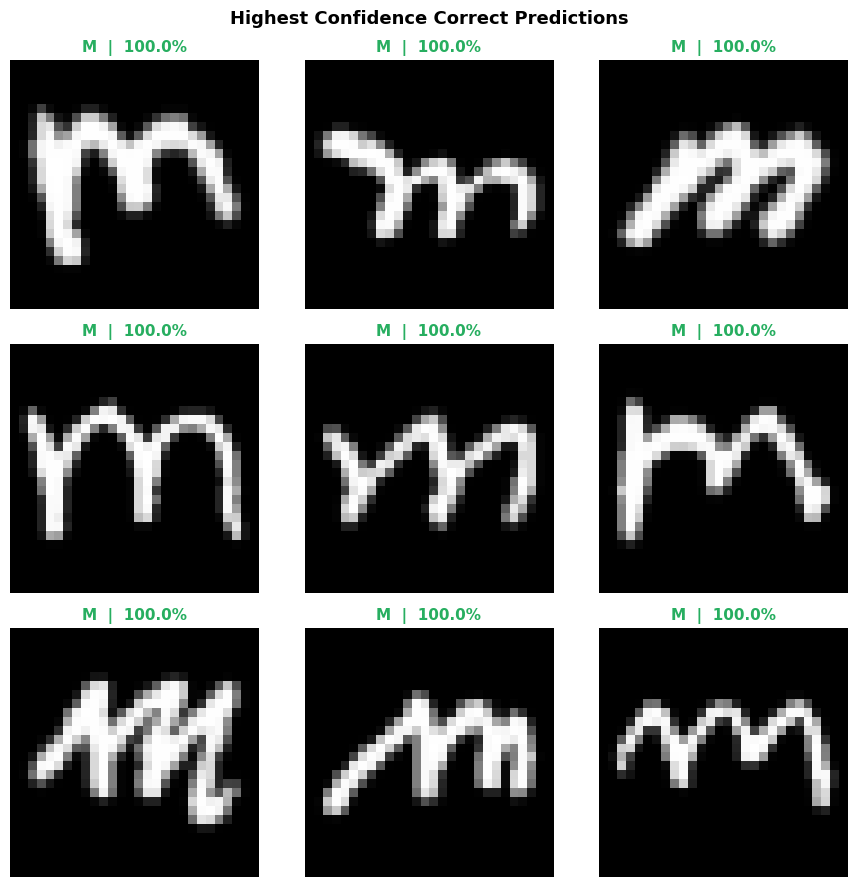

In [33]:
# 8.7 Highest-confidence correct predictions
correct_idx  = np.where(correct_mask)[0]
top9_correct = correct_idx[np.argsort(pred_confidences[correct_idx])[-9:]]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, idx in zip(axes.ravel(), top9_correct):
    ax.imshow(X_test[idx].squeeze(), cmap='gray')
    ax.axis('off')
    letter = letter_names[y_true_cls[idx]]
    conf   = pred_confidences[idx] * 100
    ax.set_title(f'{letter}  |  {conf:.1f}%', color='#27ae60', fontsize=11, fontweight='bold')
plt.suptitle('Highest Confidence Correct Predictions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


These are the model at its best: clean, distinctive letters classified with almost 100% confidence.

### 8.8 Worst-Performing Letter Examples

3 hardest letters: ['I', 'G', 'L']


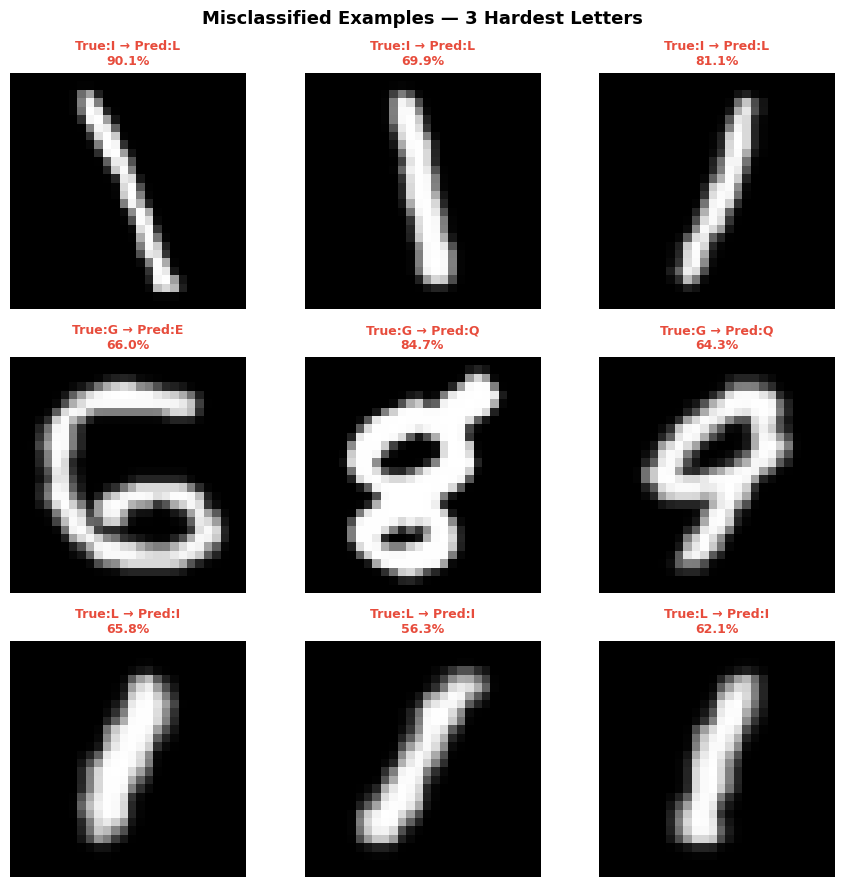

In [34]:
# 8.8 Misclassified examples for the 3 hardest letters
worst3       = np.argsort(per_class_acc)[:3]
worst_letters = [letter_names[i] for i in worst3]
print(f"3 hardest letters: {worst_letters}")

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
plot_i = 0

for ltr in worst_letters:
    ltr_idx     = ord(ltr) - 65
    wrong_for_l = [i for i in range(len(y_true_cls))
                   if y_true_cls[i] == ltr_idx and y_pred_cls[i] != ltr_idx][:3]
    for idx in wrong_for_l:
        if plot_i >= 9: break
        ax = axes.ravel()[plot_i]
        ax.imshow(X_test[idx].squeeze(), cmap='gray')
        ax.axis('off')
        ax.set_title(f"True:{letter_names[y_true_cls[idx]]} → Pred:{letter_names[y_pred_cls[idx]]}\n"
                     f"{pred_confidences[idx]*100:.1f}%",
                     color='#e74c3c', fontsize=9, fontweight='bold')
        plot_i += 1

plt.suptitle('Misclassified Examples — 3 Hardest Letters', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Why these letters are hard**

**I (54.3% recall):** an I is a single vertical stroke. At 28 × 28 the difference from an L can be 2–3 pixels at the base, and the model has learned to default to L when that base is unclear. I's precision is still 0.84, so when it does predict I it is usually right.

**G (75.0% recall):** G is most often read as Q: both have a round body with a stroke at the bottom right. G's distinguishing inner bar varies a lot between writers and is sometimes missing.

**L (86.9% recall, 0.67 precision):** L's low precision is the other side of the I problem: it absorbs many true I's.

**Ideas for these letters:**
1. Targeted augmentation for I and L
2. Focal loss or class weights that penalise mistakes on I and G more heavily
3. A second-stage classifier just for the hard pairs

## 9. Feature Map Visualisation

Feature maps reveal **what the CNN is actually looking at** when processing an image. By extracting the output of the first convolutional layer, we can see which spatial patterns each of the 32 filters has learned to detect.


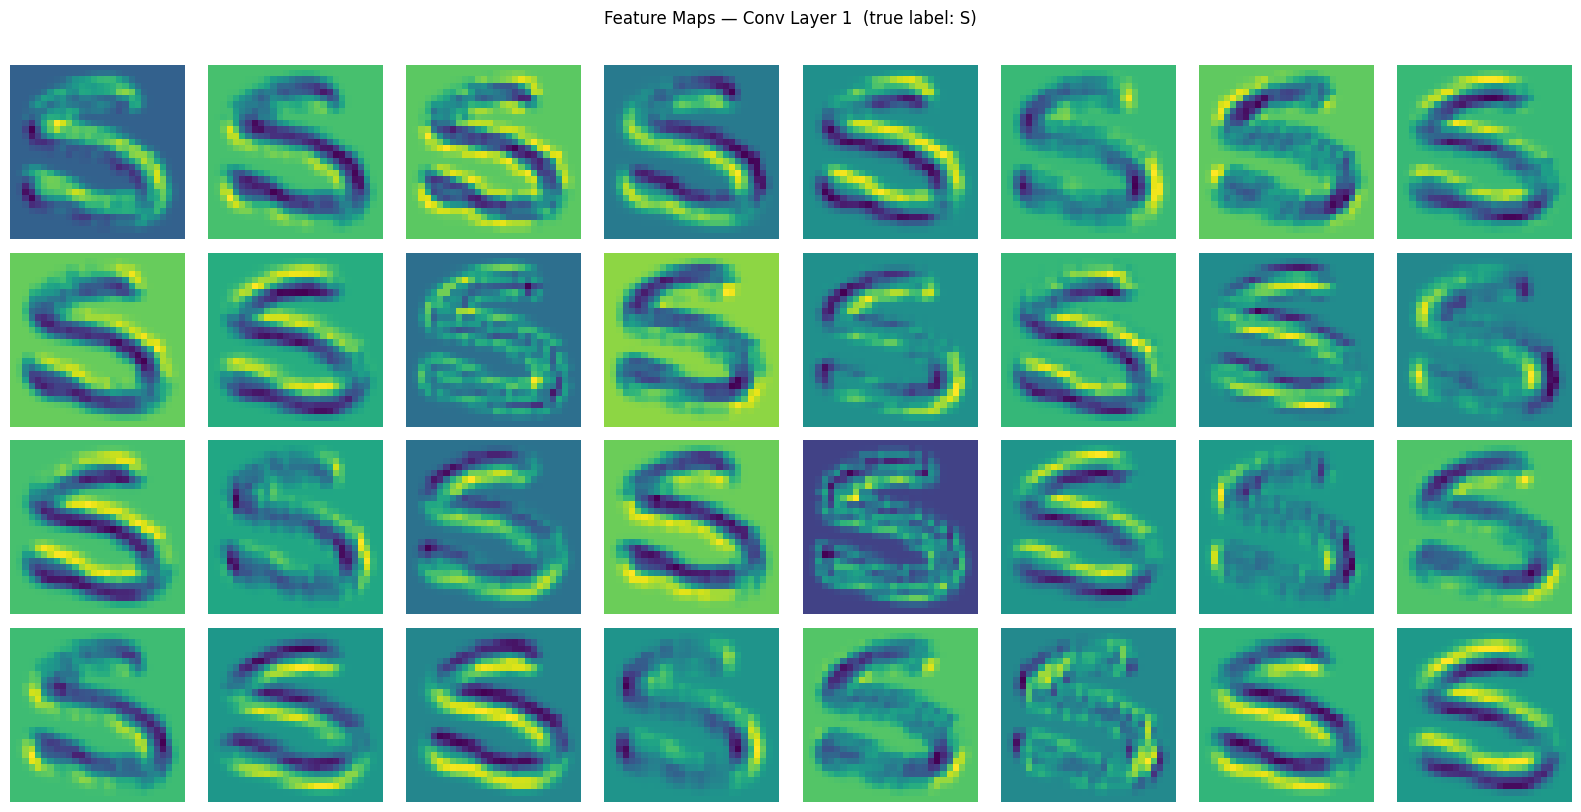

In [35]:
# Extract feature maps from the first Conv layer on one test sample
import tensorflow as tf

sample_img = X_test[0:1]   # shape (1, 28, 28, 1)

# Build a sub-model up to the first Conv layer output
feat_model = keras.Model(inputs=improved.input,
                         outputs=improved.get_layer(index=0).output)  # first conv layer
feat_maps  = feat_model.predict(sample_img, verbose=0)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flatten()):
    if i < feat_maps.shape[-1]:
        ax.imshow(feat_maps[0, :, :, i], cmap='viridis')
    ax.axis('off')
plt.suptitle(f'Feature Maps — Conv Layer 1  (true label: {letter_names[y_true_cls[0]]})',
             y=1.01)
plt.tight_layout()
plt.show()

**How to interpret feature maps:**
Each panel shows the activation of one filter across the 28×28 spatial grid when processing a specific test image. Bright regions indicate where that filter fired strongly — i.e., where the image contains the spatial pattern that filter has learned to detect.

**Expected patterns in the first Conv2D(32) layer:**
- Several filters act as **edge detectors** — high activation along specific orientations (horizontal, vertical, diagonal). These are the basic building blocks all letter recognition builds upon.
- Some filters show **stroke detectors** — activation along the main letter strokes rather than just edges.
- A few filters may appear mostly dark — these detect specific textures or combinations that happen to be absent in this particular test letter.

**Why only the first layer is visualised:**
First-layer features are still directly interpretable as spatial image patterns — they correspond to recognisable visual features (edges, curves, corners). Deeper layers combine these into increasingly abstract representations (e.g., "curve with an opening on the right" for C/G discrimination) that do not map cleanly to visually interpretable patterns.



## 10. Summary and conclusion

### 10.1 Results

| Model | Params | Test accuracy | Test loss | Best val accuracy | Training time |
|-------|:------:|:---:|:---:|:---:|:---:|
| Baseline CNN (no augmentation) | 423,706 | 93.04% | 0.2174 | 93.53% (epoch 9) | 0.7 min |
| Improved CNN, no augmentation | 62,490 | — | — | 93.66% (epoch 30) | 2.6 min |
| **Improved CNN, with augmentation** | **62,490** | **93.18%** | **0.2006** | **93.72% (epoch 26)** | 6.9 min |

### 10.2 Key findings

1. **Same accuracy, 85% fewer parameters.** Replacing `Flatten → Dense(128)` with `GlobalAveragePooling2D` removed about 397,000 parameters. The improved model matched the baseline (93.18% vs 93.04%) with a slightly lower test loss.
2. **Augmentation barely mattered here** (+0.06 points on validation). Batch normalisation and dropout were already handling most of the regularisation.
3. **Learning-rate scheduling needed time.** The improved model starts slowly, and its best results came after `ReduceLROnPlateau` fired late in training.
4. **I vs L is the main failure mode.** Only 54.3% of I's are recognised, mostly lost to L, a genuine ambiguity at this resolution.
5. **Confidence is informative.** Correct predictions average 95% confidence and wrong ones 67%.

### 10.3 Limitations and next steps

| Limitation | Impact | Next step |
|------------|--------|-----------|
| I/L confusion | I recall 54.3% | Targeted augmentation, focal loss, a classifier for hard pairs |
| Still improving at epoch 30 | A second learning-rate drop fired at the last epoch | Train for 40–50 epochs |
| One training run per model | Differences of 0.1 points are within run-to-run noise | Repeat runs with different seeds and report the spread |
| Fixed hyperparameters | Filter counts and dropout rates weren't tuned | KerasTuner search |